# Рекомендации фильмов с ENMF-U

Обучили модель на MovieLens 1M и сравнили её с рекомендациями по популярности. Для таблицы и графиков достаточно сохранённых результатов. Последняя ячейка использует датасет и веса с CPU-запуска, если они есть на диске.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import torch
from IPython.display import Markdown, display
from enmf.data import read_movielens
from enmf.model import ENMF
from enmf.plots import read_results, validation_figure
from enmf.recommend import recommend

## Какие фильмы попали в оценку

Разделили оценки по одной дате для всех пользователей. В validation оставили пары, у которых и пользователь, и фильм встречались в train. Ранжируем весь каталог train, пропуская фильмы, которые пользователь уже оценивал к этой дате.

In [2]:
results = read_results(root / "results")
cpu_run = results["CPU × 1"]
cpu_run["data"]

{'source_events': 1000209,
 'unique_pairs': 1000209,
 'train_users': 5400,
 'train_items': 3662,
 'train_pairs': 800164,
 'train_last_timestamp': 975768719,
 'cutoff_timestamp': 975768738,
 'cutoff_utc': '2000-12-02T14:52:18+00:00',
 'future_pairs': 200045,
 'validation_pairs': 104452,
 'validation_users': 1143,
 'excluded_unknown_user_only': 95478,
 'excluded_unknown_item_only': 91,
 'excluded_both_unknown': 24}

## Проверка функции потерь

Сумма квадратов оценок пользователя по всему каталогу равна \(a_u^\mathsf{T}(Q^\mathsf{T}Q)a_u\), где \(a_u=p_u\odot h\), а в строках \(Q\) лежат векторы фильмов. Для каждой наблюдаемой пары заменяем штраф \(w s_{ui}^2\) на \((1-s_{ui})^2\).

Возьмём двух пользователей и четыре фильма. На такой матрице можно посчитать взвешенную ошибку напрямую и сравнить её с формулой ENMF-U.

In [3]:
torch.manual_seed(42)
model = ENMF(num_users=2, num_items=4, embedding_dim=3, dropout=0).double()
users = torch.tensor([0, 1])
positive_rows, positive_items = torch.tensor([0, 0, 1]), torch.tensor([0, 2, 1])
missing_weight = 0.5

scores = model.scores(users)
target = torch.zeros_like(scores)
target[positive_rows, positive_items] = 1
weights = torch.where(target.bool(), 1.0, missing_weight)
dense_loss = (weights * (target - scores).square()).sum()
efficient_loss = model(users, positive_rows, positive_items, missing_weight)
torch.testing.assert_close(efficient_loss, dense_loss, rtol=1e-12, atol=1e-12)
print(f"Прямой расчёт: {dense_loss.item():.9f}")
print(f"Формула ENMF-U:  {efficient_loss.item():.9f}")

Прямой расчёт: 2.998211484
Формула ENMF-U:  2.998211484


## Качество рекомендаций

Для каждой конфигурации взяли эпоху с лучшим NDCG@10 и показали NDCG@20 и NDCG@50 с той же эпохи.

| Запуск | Эпоха | NDCG@10 | NDCG@20 | NDCG@50 |
| --- | ---: | ---: | ---: | ---: |
| Популярность | - | 0.2676 | 0.2522 | 0.2388 |
| CPU × 1 | 25 | 0.2897 | 0.2673 | 0.2532 |
| CPU × 2 (DDP) | 25 | 0.2878 | 0.2663 | 0.2516 |
| CUDA × 1 | 22 | 0.2850 | 0.2656 | 0.2516 |

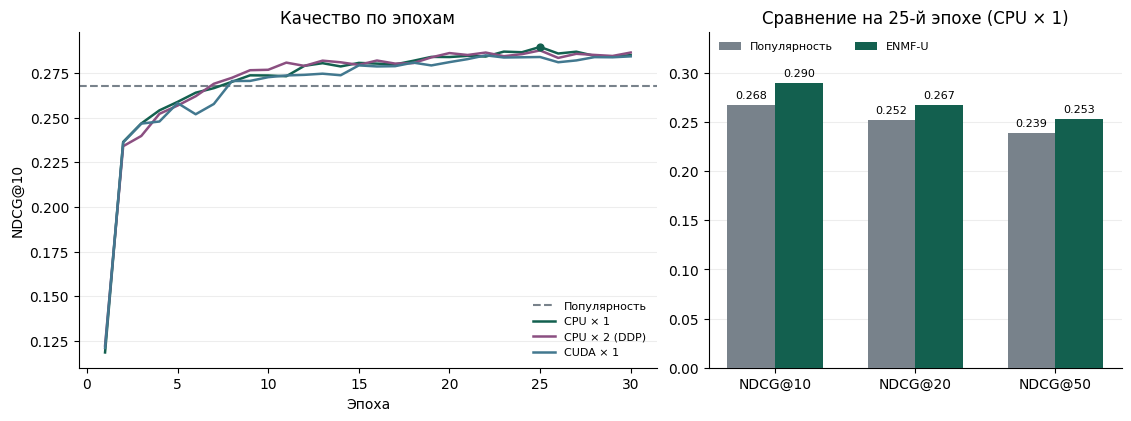

In [4]:
baseline = cpu_run["popularity"]
metrics = list(baseline)
table = [
    "| Запуск | Эпоха | " + " | ".join(key.upper() for key in metrics) + " |",
    "| --- | ---: |" + " ---: |" * len(metrics),
]
runs = [("Популярность", "-", baseline)]
runs += [(name, run["best"]["epoch"], run["best"]) for name, run in results.items()]
for name, epoch, scores in runs:
    cells = " | ".join(f"{scores[key]:.4f}" for key in metrics)
    table.append(f"| {name} | {epoch} | {cells} |")
display(Markdown("\n".join(table)))
figure = validation_figure(results)

## Пять рекомендаций

Берём первого пользователя из train и выводим названия фильмов в порядке оценок модели.

In [ ]:
checkpoint = root / "runs/cpu-1/best.pt"
dataset = root / "data/ml-1m.zip"
if checkpoint.is_file() and dataset.is_file():
    split = read_movielens(dataset, cpu_run["config"]["train_fraction"])
    user_id = int(split.user_ids[0])
    recommendations = recommend(checkpoint, user_id, k=5)
    print(f"Пользователь {user_id}")
    for rank, record in enumerate(recommendations, start=1):
        item_id = record["item_id"]
        title = split.titles.get(item_id, str(item_id))
        print(f"{rank}. {title}  ({record['score']:.4f})")
else:
    print("Для примера загрузите данные и выполните CPU-запуск по инструкции в README.")